In [1]:
import pandas as pd

In [2]:
panel_df = pd.read_csv("data/panel.csv")
person_df = pd.read_csv("data/person.csv")

In [5]:
person_df

,incident_id,person_no,dte_reported,dte_occurred,inc_hour,inc_type,inc_cause,age,sex,surfer,...,equip_rating,rocky,fishing,n_bins,rockpool,icecream_visits,surfer_prop,marine_health,incident_size,on_duty
0,1,1,2016-09-01,2016-09-01,8,Mild,Swimming_Incident,72,M,0.0,...,50,0,0,45,1,3.9,0.178,H,1,1
1,2,1,2016-09-01,2016-09-01,9,Mild,Physical_injury,30,M,0.0,...,58,1,1,57,0,3.2,0.144,H,1,1
2,3,1,2016-09-01,2016-09-01,9,CloseCall,Swimming_Incident,41,M,unknown,...,48,0,0,19,1,2.0,0.123,M,1,0
3,4,1,2016-09-01,2016-09-01,10,Mild,Swimming_Incident,9,M,0.0,...,76,0,1,44,1,4.4,0.587,H,1,1
4,5,1,2016-09-01,2016-09-01,11,CloseCall,Swimming_Incident,39,F,0.0,...,50,0,0,45,1,3.9,0.178,H,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33936,32455,1,2026-08-31,2026-08-31,12,Mild,Swimming_Incident,22,M,0.0,...,54,1,1,10,0,0.6,0.204,L,1,0
33937,32456,1,2026-08-31,2026-08-31,13,Mild,Swimming_Incident,16,M,0.0,...,88,0,0,26,0,2.6,0.254,M,1,0
33938,32457,1,2026-08-31,2026-08-31,14,Mild,Swimming_Incident,61,F,0.0,...,83,0,0,46,0,3.8,0.126,M,1,1
33939,32458,1,2026-08-31,2026-08-31,14,Mild,Swimming_Incident,4,M,0.0,...,83,0,0,46,0,3.8,0.126,M,1,1


In [3]:
panel_df

,beach_nm,postcode,month,visitors,shore_len_m,n_rips,air_temp_hi,swell_avg_m,swell_max_m,wind_days,...,n_bins,rockpool,icecream_visits,surfer_prop,marine_health,n_incidents,n_people,n_closecall,n_mild,n_severe
0,Bondi Beach,2026,09/2016,67164,546,3.1,17.9,0.91,1.94,14,...,46,0,3.6,0.160,M,10,12,2,10,0
1,Bondi Beach,2026,10/2016,135166,546,3.1,21.0,0.51,0.93,12,...,46,0,5.1,0.108,M,54,55,7,46,2
2,Bondi Beach,2026,11/2016,159258,546,3.1,23.3,0.63,1.34,12,...,46,0,4.8,0.139,H,6,6,0,6,0
3,Bondi Beach,2026,12/2016,195090,546,3.1,24.4,0.64,1.10,6,...,46,0,5.5,0.139,H,32,35,3,30,2
4,Bondi Beach,2026,01/2017,264337,546,3.1,25.8,1.05,2.22,6,...,46,0,6.0,0.107,L,61,65,5,60,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9595,Aslings Beach (Eden),2551,04/2026,5073,583,2.8,19.9,0.64,1.19,5,...,11,1,3.4,0.112,L,4,4,1,3,0
9596,Aslings Beach (Eden),2551,05/2026,2379,583,2.8,19.1,1.35,2.55,5,...,11,1,1.6,0.205,L,0,0,0,0,0
9597,Aslings Beach (Eden),2551,06/2026,1914,583,2.8,19.4,1.29,2.77,11,...,11,1,1.3,0.179,L,0,0,0,0,0
9598,Aslings Beach (Eden),2551,07/2026,2133,583,2.8,15.0,1.37,2.78,6,...,11,1,0.4,0.150,M,0,0,0,0,0


### Incident Severity Distribution

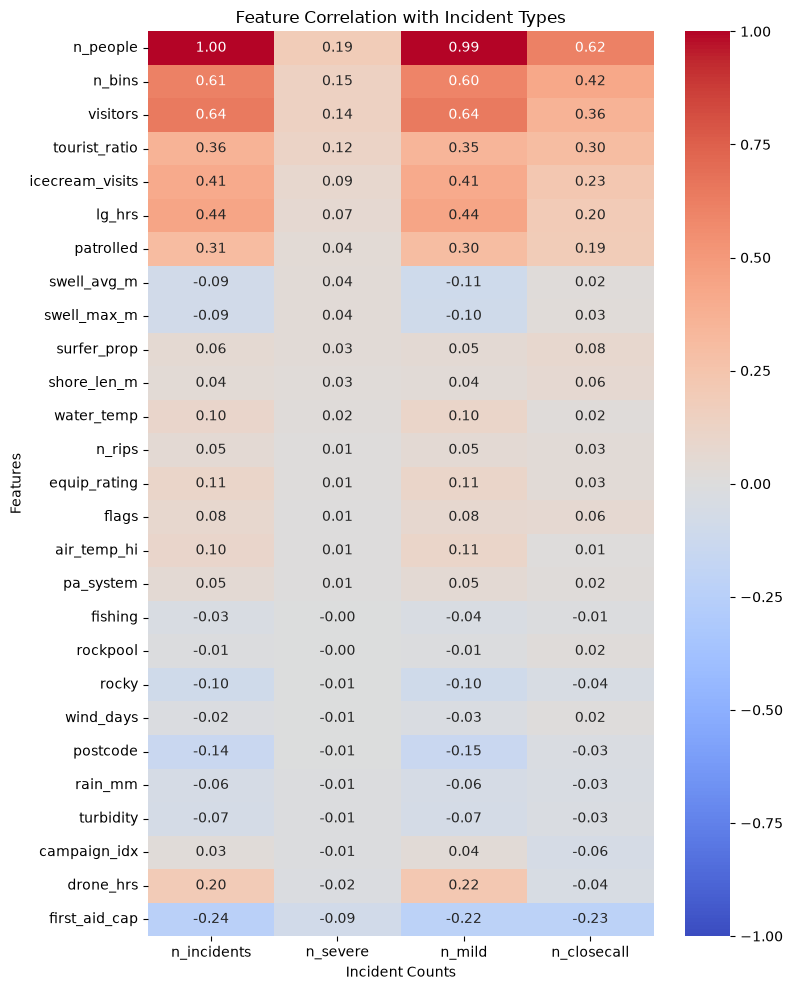

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = panel_df.select_dtypes(include=['number'])

# Calculate the correlation matrix
corr_matrix = numeric_cols.corr()

# Define the target variables we care most about
targets = ['n_incidents', 'n_severe', 'n_mild', 'n_closecall']

# Filter the matrix to show how all features correlate with just the targets
# Dropping the targets from the rows prevents a redundant 1.00 correlation block
target_corr = corr_matrix[targets].drop(targets).sort_values(by='n_severe', ascending=False)

# Create the heatmap
plt.figure(figsize=(8, 10))
sns.heatmap(target_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Feature Correlation with Incident Types')
plt.ylabel('Features')
plt.xlabel('Incident Counts')
plt.tight_layout()
plt.show()

<Axes: >

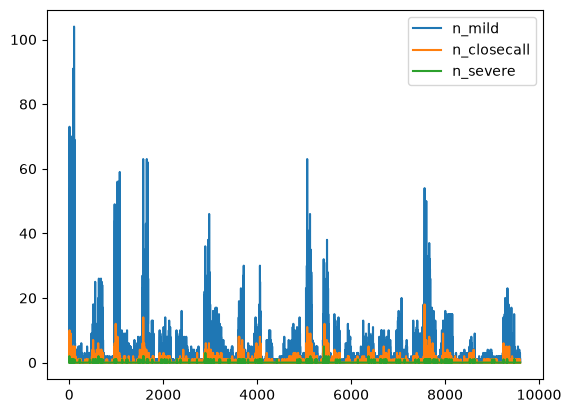

In [4]:
panel_df[["n_mild", "n_closecall", "n_severe"]].plot()